#  Criatura lendária: Tiamat

## Introdução

escrever aqui

## Importando o dataset

Primeiro, vamos importar um dataset da UCI sobre informações de pacientes gravemente doentes de 5 diferentes centros médicos do EUA. Dentre os atributos, temos os históricos hospitalares dessas pessoas com diferentes doenças, como insuficiência respiratória aguda, doença hepática, coma, câncer de cólon, entre outras. O objetivo original deste conjunto de dados é determinar as taxas de sobrevivência desses pacientes em 2 e 6 meses, com base em diversas informações fisiológicas, demográficas e de gravidade da doença. Entretanto, nesse notebook vamos determinar apenas um target, que será identificar morte durante a internação (y = hospdead). 

In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
support2 = fetch_ucirepo(id=880) 

X = support2.data.features 
y = support2.data.targets 

X

,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,7.000000
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,1.000000
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,0.000000
3,42.38498,female,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,...,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,0.000000
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,...,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,2.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9100,66.07300,male,ARF/MOSF w/Sepsis,ARF/MOSF,1,8.0,NaN,0.0,52870.0,34329.3125,...,0.399963,1.099854,131.0,7.459961,188.0,21.0,NaN,NaN,0.0,0.000000
9101,55.15399,female,Coma,Coma,1,11.0,NaN,41.0,35377.0,23558.5000,...,NaN,5.899414,135.0,7.289062,190.0,49.0,0.0,NaN,0.0,0.000000
9102,70.38196,male,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,0.0,46564.0,31409.0156,...,0.399963,2.699707,139.0,7.379883,189.0,60.0,3900.0,NaN,NaN,2.525391
9103,47.01999,male,MOSF w/Malig,ARF/MOSF,1,13.0,NaN,0.0,58439.0,NaN,...,0.399963,3.500000,135.0,7.469727,246.0,55.0,NaN,NaN,0.0,0.000000


## Tratamento de dados 

Nesta etapa, vamos tratar os dados desse dataset, e com isso, limpar e organizar esses dados para depois, conseguirmos criar modelos com os diferentes algoritmos. 

### Problema 1 do dataset

Neste dataset, é visto que algumas colunas possuem informações que o modelo não deveria ter para prever a morte do paciente. Por exemplo, a coluna "charges" informa o custo total da internação, e isso só é calculado quando a internação acaba, tal informação que o médico não tem ao cuidar do indivíduo. Além disso, podemos observar colunas como "surv2m" e "surv6m", que são probabilidades de sobrevivência calculadas por outros modelos a partir dos mesmos exames, e com esses valores, o nosso modelo pode só copiar esses outros modelos e não criar um padrão em si. Para obtermos um modelo útil, precisamos retirar esses tipos de colunas.

Assim, vamos nos orientar por uma afirmação, sendo ela: **Considerando o dia 3 de internação, com as informações disponíveis até então para o médico, será previsto se o paciente morrerá durante a internação (hospdead)**. Os modelos vão ser feitos com base nisso pois quase todos os exames e sinais vitais do dataset foram medidos no dia 3, e assim, uma coluna apenas será considerada se já for conhecida no dia 3 para o médico. Desse modo, as informações do futuro e de outros modelos citada no outro paragrafo serão desconsideradas.

Para resolver isso, vamos investigar coluna por coluna e decidir quais serão usadas para os modelos e quais serão descartadas. Diante isso, foi criado dois dicionários para dividir os atributos entre úteis e descartavéis, e no valor de cada chave temos a explicação do porque tal atributo foi escolhido ou não.

Para fazer isto, vamos ler a descrição de cada um dos atributos feita pelo próprio dataset

In [2]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

info = support2.variables.set_index('name')

for col in X.columns:
    print(f"{col}  ({info.loc[col, 'type']})")
    print(f"   {info.loc[col, 'description']}\n")

age  (Continuous)
   Age of the patients in years

sex  (Categorical)
   Gender of the patient. Listed values are {male, female}.

dzgroup  (Categorical)
   The patient's disease sub category amogst ARF/MOSF w/Sepsis, CHF, COPD, Cirrhosis, Colon Cancer, Coma, Lung Cancer, MOSF w/Malig.

dzclass  (Categorical)
   The patient's disease category amongst "ARF/MOSF", "COPD/CHF/Cirrhosis", "Cancer", "Coma".

num.co  (Continuous)
   The number of simultaneous diseases (or comorbidities) exhibited by the patient. Values are ordinal with higher values indicating worse condition and chances of survival.

edu  (Categorical)
   Years of education

income  (Categorical)
   Income of the patient. Listed values are {"$11-$25k", "$25-$50k", ">$50k", "under $11k"}.

scoma  (Continuous)
   SUPPORT day 3 Coma Score based on Glasgow scale (predicted by a model).

charges  (Continuous)
   Hospital charges

totcst  (Continuous)
   Total ratio of costs to charges (RCC) cost

totmcst  (Continuous)
   Total mi

Com isso, foi possível dividir os atributos em úteis para o projeto e descartavéis por trazerem potencialmente alguma falha para os modelos. Depois disso, vamos checar se todos os atributos foram divididos nos dois dicionários.

In [3]:
atributo_util = {
    "age, sex, edu, income, race": "informaçoes conhecidas desde a entrada",
    "dzgroup": "diagnóstico do paciente conhecido na entrada dele",
    "dzclass": "versão mais ampla do dzgroup",
    "num.co, dementia, diabetes, ca": "doenças e comorbidades prévias do paciente",
    "hday": "dia de internação que o paciente entrou no estudo",
    "meanbp, hrt, resp, temp": "sinais vitais medidos no dia 3",
    "wblc, pafi, alb, bili, crea, sod, ph, glucose, bun, urine": "exames e medidas do dia 3",
    "adlp": "indice de atividade diaria respondido pelo paciente",
    "adlsc": "versão completa do adls"
}
atributo_descarte = {
    "scoma, sps, aps, surv2m, surv6m": "previsão de outro modelo",
    "charges, totcst, totmcst": "informação obtida depois do terceiro dia (custos totais da internação)",
    "avtisst": "informação obtida depois do terceiro dia",
    "prg2m, prg6m": "Estimativas de sobrevivência feitas pelos médicos com relação ao desfecho",
    "dnr, dnrday": "pode ser posterior ao dia 3 e tem alta relação com o desfecho",
    "adls": "indice de atividade diaria respondido por outra pessoa, muito correlacionado com adlsc"
}

def expandir(d):
    return {col.strip(): motivo
            for chaves, motivo in d.items()
            for col in chaves.split(",")}

atributo_util = expandir(atributo_util)
atributo_descarte = expandir(atributo_descarte)

todas = set(X.columns)
classificadas = set(atributo_util) | set(atributo_descarte)
print(todas - classificadas)   # esquecidas
print(classificadas - todas)  

set()
set()


mas ainda temos problemas para resolver....

### Problema 2 do dataset

Após essa primeira organização do dataset, temos em vista um novo problema, os dados faltantes:

In [4]:
X[list(atributo_util)].isna().mean().sort_values(ascending=False)

adlp        0.619550
urine       0.533992
glucose     0.494234
bun         0.477979
alb         0.370346
income      0.327512
bili        0.285667
pafi        0.255354
ph          0.250851
edu         0.179462
wblc        0.023284
crea        0.007359
race        0.004613
meanbp      0.000110
resp        0.000110
temp        0.000110
sod         0.000110
hrt         0.000110
hday        0.000000
age         0.000000
sex         0.000000
ca          0.000000
diabetes    0.000000
dementia    0.000000
num.co      0.000000
dzclass     0.000000
dzgroup     0.000000
adlsc       0.000000
dtype: float64

Vamos plotar um gráfico desses dados.

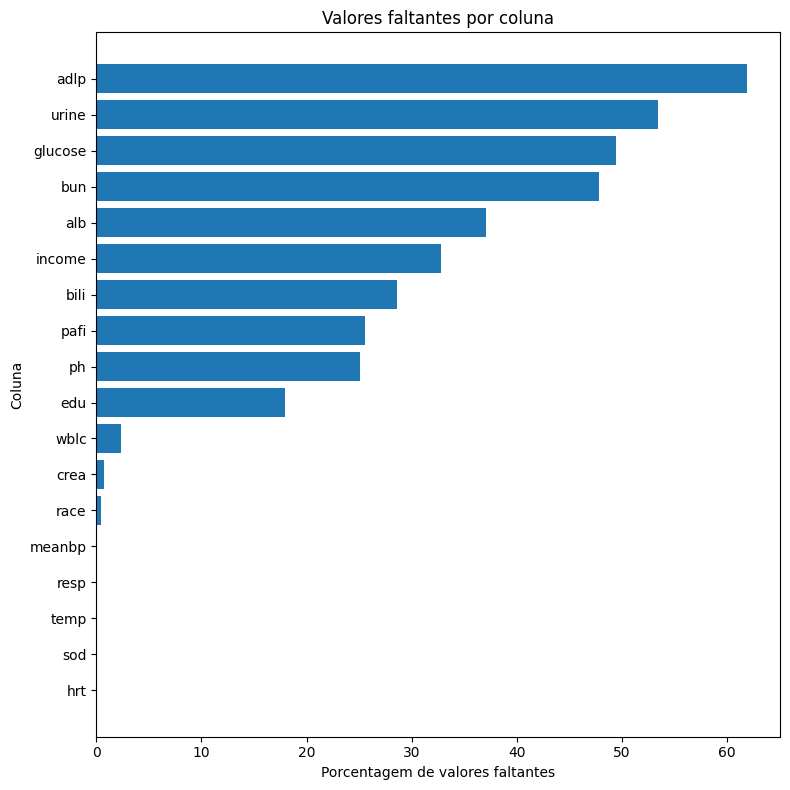

In [5]:
import matplotlib.pyplot as plt

# porcentagem de faltantes por coluna (só das que têm algum faltante)
colunas_uteis = list(atributo_util)
faltantes = X[colunas_uteis].isna().mean().sort_values(ascending=False) * 100
faltantes = faltantes[faltantes > 0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(faltantes.index, faltantes.values)
ax.invert_yaxis()   # a coluna com mais faltantes fica no topo
ax.set_xlabel("Porcentagem de valores faltantes")
ax.set_ylabel("Coluna")
ax.set_title("Valores faltantes por coluna")
plt.tight_layout()
plt.show()

Como podemos notar na tabela e no gráfico acima, existem atributos com muitos dados faltantes que podem prejudicar os nossos modelos.

Vamos dividir em 3 grupos diferentes:
1. atributos com menos de 25% dos dados faltantes --> como a maior parte desses dados está preenchida, então nos faltantes será colocado a mediana dos dados que temos
2. atributos com faltantes entre 25% e 50% --> nesse caso os faltantes já começam a ser mais relevante, porém na sua maioria são exames laboratoriais, e podem estar faltando porque o médico não pediu certos exames, uma vez que não seriam relevantes para aquele caso. Para os outros casos, temos dados faltantes com falta de informação mesmo. Logo, nessas informações faltantes será indicado que elas estão faltando com um valor específico, além de também serem preenchidos com a mediana.
3. atributos com mais de 50% dos dados faltantes --> serão descartados, pois as informações que temos nessas colunas são a minoria.

Assim, atualizando os nossos dicionários, temos:

In [6]:
atributo_util = {
    "age, sex, edu, income, race": "informaçoes conhecidas desde a entrada",
    "dzgroup": "diagnóstico do paciente conhecido na entrada dele",
    "dzclass": "versão mais ampla do dzgroup",
    "num.co, dementia, diabetes, ca": "doenças e comorbidades prévias do paciente",
    "hday": "dia de internação que o paciente entrou no estudo",
    "meanbp, hrt, resp, temp": "sinais vitais medidos no dia 3",
    "wblc, pafi, alb, bili, crea, sod, ph, glucose, bun": "exames e medidas do dia 3",
    "adlsc": "versão completa do adls"
}
atributo_descarte = {
    "scoma, sps, aps, surv2m, surv6m": "previsão de outro modelo",
    "charges, totcst, totmcst": "informação obtida depois do terceiro dia (custos totais da internação)",
    "avtisst": "informação obtida depois do terceiro dia",
    "prg2m, prg6m": "Estimativas de sobrevivência feitas pelos médicos com relação ao desfecho",
    "dnr, dnrday": "pode ser posterior ao dia 3 e tem alta relação com o desfecho",
    "urine, adlp" : "tem muitos dados faltantes",
    "adls": "indice de atividade diaria respondido por outra pessoa, muito correlacionado com adlsc"
}

def expandir(d):
    return {col.strip(): motivo
            for chaves, motivo in d.items()
            for col in chaves.split(",")}

atributo_util = expandir(atributo_util)
atributo_descarte = expandir(atributo_descarte)

todas = set(X.columns)
classificadas = set(atributo_util) | set(atributo_descarte)
print(todas - classificadas)   # esquecidas
print(classificadas - todas)  


set()
set()


Por fim, foi verificado a existencia de linhas duplicadas e foi visto que elas não existem nesse dataset, ou seja, todas as linhas são de pacientes diferentes, assim, podemos seguir para o próximo passo. 

### Análise do target 

Vamos analisar se o nosso target está desbalanceado plotando um gráfico dos alvos possíveis.

hospdead
0    6745
1    2360
Name: count, dtype: int64
hospdead
0    74.1
1    25.9
Name: proportion, dtype: float64


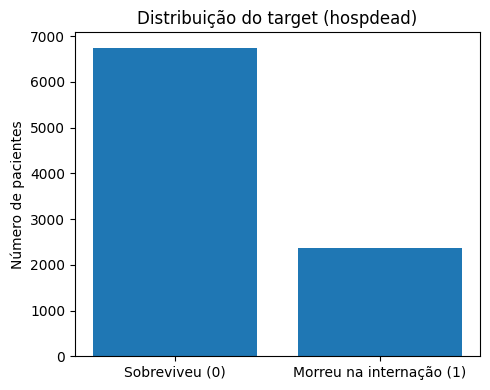

In [7]:
import matplotlib.pyplot as plt

contagem = y["hospdead"].value_counts()
proporcao = y["hospdead"].value_counts(normalize=True) * 100
print(contagem)
print(proporcao.round(1))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Sobreviveu (0)", "Morreu na internação (1)"], contagem.sort_index().values)
ax.set_ylabel("Número de pacientes")
ax.set_title("Distribuição do target (hospdead)")
plt.tight_layout()
plt.show()

Com essas informações, temos um desbalanceamento moderado, uma vez que aproximadamente 1/4 dos pacientes morreram na internação. Entretanto, sabemos que um modelo extremamentre simples que sempre prevê que um paciente sobreviveu acerta 74.1% das vezes (acuracia alta sem aprender nada). Por isso, esse será o piso de comparação (como será visto no modelo de baseline) e outras métricas também serão medidas. 

## Divisão em treino e teste 

Antes de tudo, vamos separar os dados em treino e teste, para não ocorrer vazamento de dados nesse projeto.

In [8]:
from sklearn.model_selection import train_test_split

X_util = X[list(atributo_util)]
y_alvo = y["hospdead"]

X_train, X_test, y_train, y_test = train_test_split(
    X_util, y_alvo,
    test_size=0.2,
    stratify=y_alvo,
    random_state=8,
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(7284, 26) (1821, 26)
0.259 0.259


Os dados foram divididos na proporção de 80% para treino e 20% para teste apenas as colunas consideradas uteis para o projeto, definida pelos dicionários na etapa anterior. Além disso, os dados foram estratificados para manter a mesma proporção de morte (~26%) nos dados de treino e teste. Uma semente aleatória foi fixada para promover reprodutibilidade.

## Análise exploratória de dados 

Essa análise será feita apenas com base nos dados de treino. Primeiro, vamos usar o describe para observar um conjunto estatistico dos dados.

In [9]:
X_train.describe()


,age,edu,num.co,dementia,diabetes,hday,meanbp,hrt,resp,temp,wblc,pafi,alb,bili,crea,sod,ph,glucose,bun,adlsc
count,7284.000000,5977.000000,7284.000000,7284.000000,7284.000000,7284.000000,7283.000000,7283.000000,7283.000000,7283.000000,7121.000000,5398.000000,4598.000000,5215.000000,7231.000000,7283.000000,5435.000000,3681.000000,3797.000000,7284.000000
mean,62.654291,11.721432,1.880011,0.031713,0.198243,4.328803,84.400110,97.128972,23.380887,37.097398,12.368345,240.235698,2.949777,2.545680,1.780262,137.552520,7.415483,159.460907,32.387332,1.882515
std,15.625096,3.448589,1.350400,0.175248,0.398703,8.895363,27.548514,31.522144,9.607009,1.253917,9.474916,109.118910,0.892550,5.297516,1.714496,6.050219,0.080633,88.415083,26.465730,2.003054
min,18.041990,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,32.000000,0.000000,12.000000,0.399963,0.099991,0.099991,110.000000,6.829102,0.000000,1.000000,0.000000
25%,52.805235,10.000000,1.000000,0.000000,0.000000,1.000000,63.000000,72.000000,18.000000,36.093750,6.899414,157.031250,2.399902,0.500000,0.899902,134.000000,7.379883,102.000000,14.000000,0.000000
50%,64.882965,12.000000,2.000000,0.000000,0.000000,1.000000,77.000000,100.000000,24.000000,36.695310,10.500000,224.437500,2.899902,0.899902,1.199951,137.000000,7.419922,134.000000,24.000000,1.000000
75%,73.986240,14.000000,3.000000,0.000000,0.000000,3.000000,107.000000,120.000000,28.000000,38.093750,15.298828,306.625000,3.599609,1.899902,1.899902,141.000000,7.469727,188.000000,42.000000,3.000000
max,100.849000,31.000000,9.000000,1.000000,1.000000,147.000000,195.000000,300.000000,90.000000,41.695310,200.000000,890.375000,29.000000,54.796875,21.500000,181.000000,7.769531,1092.000000,192.000000,7.073242


Com isso, podemos extrair algumas informações, como por exemplo a idade média dos pacientes fica em torno de 62 anos. Na maioria dos atributos, a média e a mediana (50%) estão próximas, o que indica que nessas colunas não temos valores muito longe dos outros, e assim, apresenta simetria. Mas isso é um palpite, então agora vamos observar a distribuição de alguns atributos.

Na próxima célula vamos observar a distribuição numérica de alguns atributos com poucas categorias e ver a relação de cada um deles com a taxa de morte na internação.

In [10]:
treino = X_train.copy()
treino["hospdead"] = y_train

for col in ["sex", "race", "income", "ca", "dzgroup", "dementia", "diabetes"]:
    resumo = treino.groupby(col, dropna=False)["hospdead"].agg(["count", "mean"])
    resumo.columns = ["pacientes", "taxa_morte"]
    print(col)
    print(resumo.round(3))
    print()

sex
        pacientes  taxa_morte
sex                          
female       3196       0.261
male         4088       0.258

race
          pacientes  taxa_morte
race                           
asian            64       0.391
black          1142       0.276
hispanic        227       0.247
other            95       0.295
white          5719       0.253
NaN              37       0.405

income
            pacientes  taxa_morte
income                           
$11-$25k         1208       0.237
$25-$50k          833       0.236
>$50k             558       0.226
under $11k       2309       0.250
NaN              2376       0.295

ca
            pacientes  taxa_morte
ca                               
metastatic       1492       0.172
no               4774       0.261
yes              1018       0.377

dzgroup
                   pacientes  taxa_morte
dzgroup                                 
ARF/MOSF w/Sepsis       2816       0.340
CHF                     1107       0.064
COPD                 

Como podemos observar, em alguns atributos a taxa de morte não varia significamente entre as categorias, como no caso de "sex", em que a distribuição entre homens e mulheres é parecida. Todavia, temos outros atributos com diferenças mais significantes, como o atributo "dzgroup", em que a taxa de morte varia muito entre cancer de colo (5,5%) e coma (60%) por exemplo, mostrando assim, que este atributo é importante para a previsão do target nos modelos.

Diante disso, vamos analisar a distribuição dos valores de alguns atributos em histogramas.

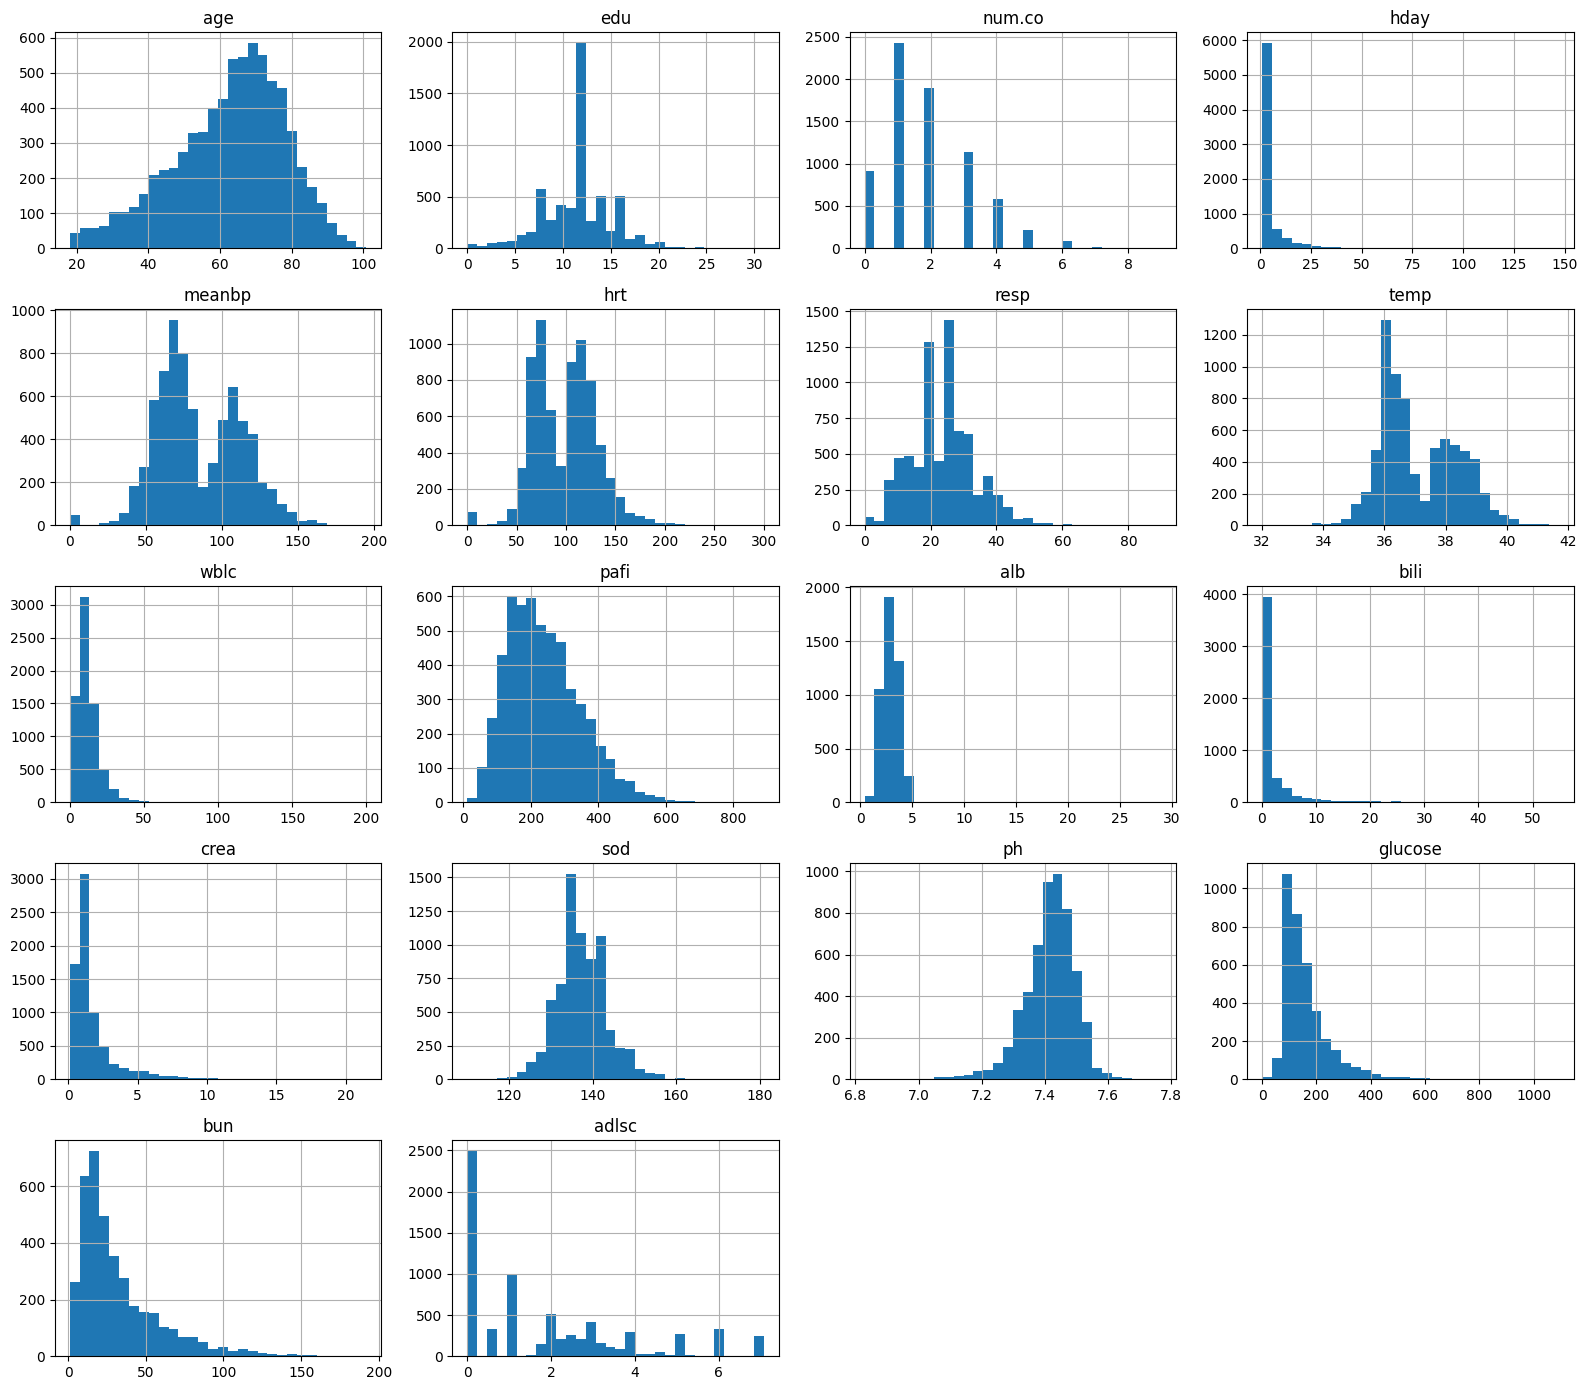

In [11]:
numericas = ["age", "edu", "num.co", "hday", "meanbp", "hrt", "resp", "temp",
             "wblc", "pafi", "alb", "bili", "crea", "sod", "ph", "glucose", "bun", "adlsc"]

X_train[numericas].hist(bins=30, figsize=(16, 14))
plt.tight_layout()
plt.show()

Podemos observar que a maioria dos gráficos possui uma distribuição variada dos valores, porém, temos alguns dados estranhos, como pacientes com a respiração ("resp"), batimento cardiaco ("hrt") e a pressão arterial média ("meanbp") zerados, o que seria impossível para um indivíduo vivo. Contudo, essa proporção é muito pequena em relação ao resto dos dados (menos de 1%). Logo, irei manter pois afetam menos de 1% das linhas e os modelos de árvores são pouco sensíveis a isso. Se isso afetar modelos como o K-NN, irei corrigir isso.

Agora nesta etapa, vamos comparar essa distribuição dos atributos visto anteriormente com a distribuição do target, para observar se os pacientes mortos possuem valores diferentes em comparação aos pacientes vivos para cada atributo analisado no último histograma. Os atributos que mostram diferenças claras no deslocamento das curvas serão mais informativos. 

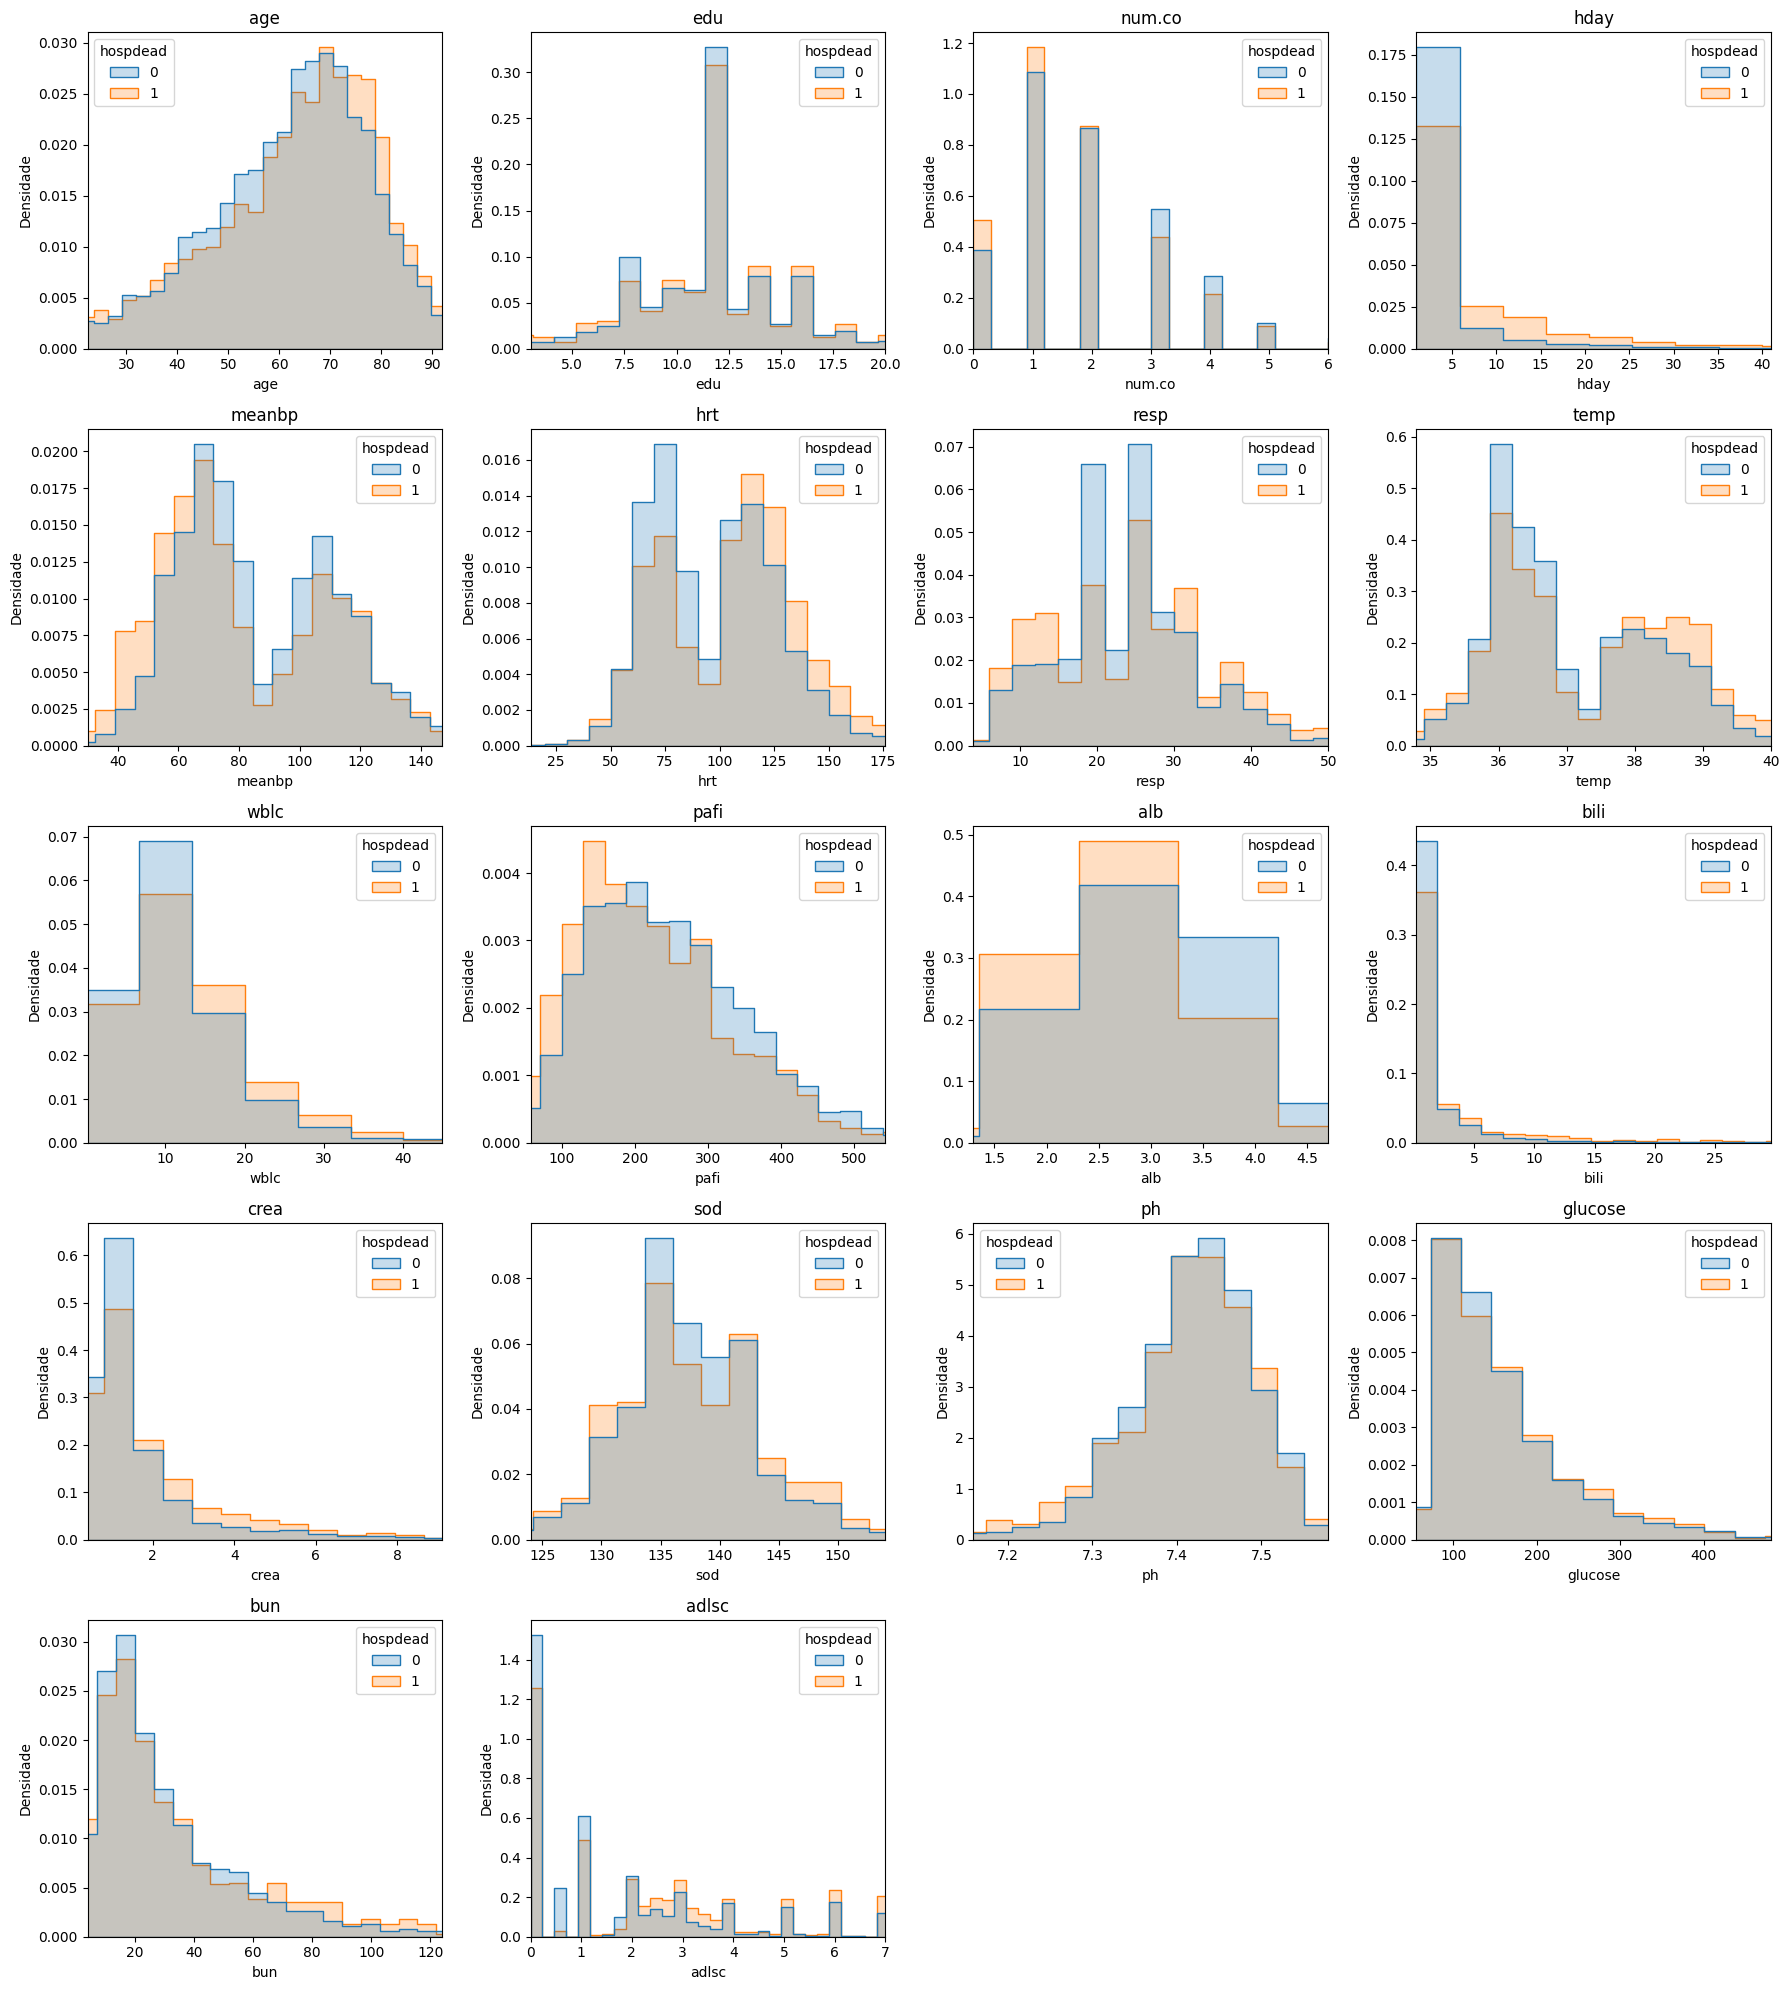

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

treino = X_train.copy()
treino["hospdead"] = y_train

fig, axes = plt.subplots(5, 4, figsize=(18, 20))
axes = axes.flatten()

for ax, col in zip(axes, numericas):
    sns.histplot(data=treino, x=col, hue="hospdead", bins=30,
                 stat="density", common_norm=False, element="step", ax=ax)
    # só para visualização: corta as caudas extremas (1% de cada lado)
    ax.set_xlim(treino[col].quantile(0.01), treino[col].quantile(0.99))
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Densidade")

for ax in axes[len(numericas):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Como pode ser visto, atributos como "alb", "hrt" e "bili" possuem diferenças claras na sua distribuição, enquanto em "resp" e "sod" temos mortos mais nos extremos dos dois lados. Por fim, atributos como "edu" e "bun" apresentaram pouca diferença.

Com isso, vamos fazer um mapa da Correlação de Spearman para analisar se as variáveis (atributos) são parecidas entre si, ou se cada coluna traz uma informação diferente. Se a correlação de dois atributos for muito alta, é valido assumir que existe uma redundância ali.

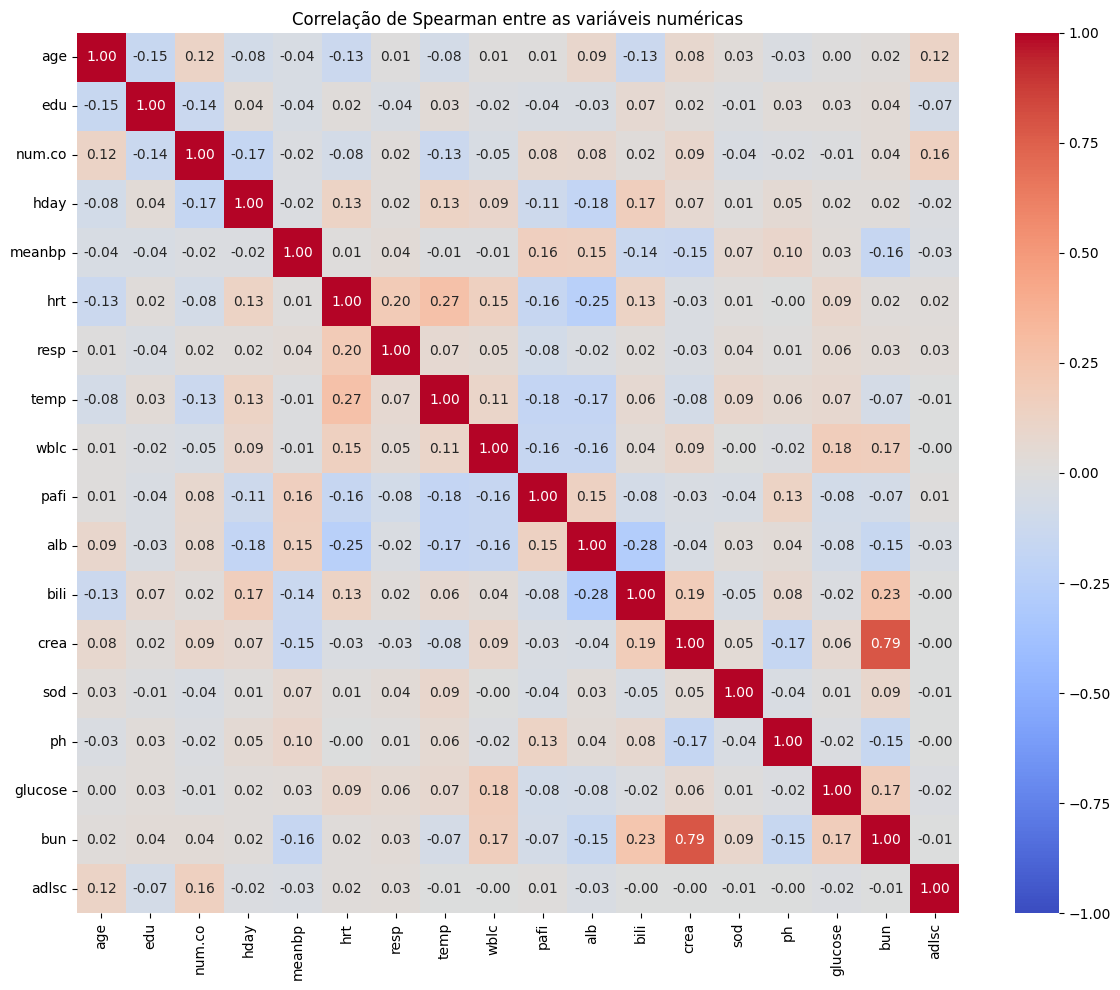

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = treino[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout()
plt.show()

Assim, é notório que os únicos atributos com valor de correlação mais alto é a variável "bun" e "crea", o que faz sentido, já que esses dois exames estão ligados à funções dos rins. 

Com isso, vamos para o pré-processamento dos dados.

## Pré-processamento 

Primeiro, vamos dividir as colunas em 3 tipos, pois cada dado exige um tratamento diferente para os modelos. Foi dividido em grupo de números (como idade), grupo de valores binários(como sexo) e categorias em texto (como renda). Por fim, foi verificado se alguma coluna não foi colocada na divisão em grupos.

In [14]:
cols_num = ["age", "edu", "num.co", "hday", "meanbp", "hrt", "resp", "temp",
            "wblc", "pafi", "alb", "bili", "crea", "sod", "ph", "glucose",
            "bun", "adlsc"]
cols_bin = ["sex", "dementia", "diabetes"]
cols_cat = ["race", "dzgroup", "dzclass", "ca", "income"]

todas_cols = cols_num + cols_bin + cols_cat
print(len(todas_cols), set(todas_cols) == set(X_train.columns))   


26 True


Olhando primeiro para as númericas, podemos observar que possuem diversos valores faltantes. Assim, vamos preencher os faltantes com a mediana dos valores dos atributos com 25% a 50% de dados faltantes. Além disso, vamos criar uma coluna extra que indica que o valor esta faltando, para colunas com muitos faltantes, uma vez que certos valores podem estar faltando por motivos externos, como exames que os médicos não pediram para certos casos. 

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import numpy as np

cols_num_ind = ["glucose", "bun", "alb", "bili", "pafi", "ph"]
cols_num_simples = [c for c in cols_num if c not in cols_num_ind]

prep_num = ColumnTransformer([
    ("num_ind", SimpleImputer(strategy="median", add_indicator=True), cols_num_ind),
    ("num_simples", SimpleImputer(strategy="median"), cols_num_simples),
])
# o simpleimputer substitui os NaN pela mediana dos valores e o add_indicator coloca uma coluna indicando 
# colunas com muitos faltantes 

Xt = prep_num.fit_transform(X_train)
# fit calcula a mediana e transform aplica o preenchimento 
print(Xt.shape)

(7284, 24)


Como podemos ver, agora temos 24 colunas desse grupo, ou seja, 18 colunas originais e 6 novas colunas indicadoras de muitos valores faltantes.

Assim, vamos analisar o grupo dos valores categóricos. Vamos transformar cada uma dessas opções em colunas de 0 e 1 com o OneHotEncoder, para os modelos conseguirem entender esses atributos.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# pipeline é a receita --> passo a passo a ser seguido
prep_cat = Pipeline([
    # strategy diz pra preencher com valor constante
    ("Passo A", SimpleImputer(strategy="constant", fill_value="desconhecido")),
    ("Passo B", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    # handle_unknown lida com erros de categorias desconhecidas e só tranforma eles em zero, e o 
    # sparse_output faz o resultado vir em uma tabela comum
])

Xc = prep_cat.fit_transform(X_train[cols_cat])
#fit_tranform aplica a receita 
print(Xc.shape)

(7284, 26)


Este código troca os faltantes pelo valor "desconhecido" (quem faz isso é o SimpleImputer) e cria colunas de 0/1 para cada categoria (quem faz isso é o OneHotEncoder). Na saída, podemos ver os 7284 pacientes e as 26 colunas de 0/1.

Dessa maneira, vamos aplicar a mesma ideia para valores binários, tranformando em apenas uma coluna que representa o 0 ou o 1. 

In [17]:
prep_bin = OneHotEncoder(drop="if_binary", sparse_output=False)

Xb = prep_bin.fit_transform(X_train[cols_bin])
print(Xb.shape)
print(prep_bin.get_feature_names_out(cols_bin))

(7284, 3)
['sex_male' 'dementia_1' 'diabetes_1']


Com tudo isso feito, vamos juntar tudo com o ColumnTransformer, que aplica cada tratamento ao seu grupo de colunas e retorna o resultado. Somando todas as colunas obtidas, agora temos 53 colunas, sem nenhum valor faltante.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import numpy as np

cols_num_ind = ["glucose", "bun", "alb", "bili", "pafi", "ph"]
cols_num_simples = [c for c in cols_num if c not in cols_num_ind]

preprocessador = ColumnTransformer([
    ("num_ind", SimpleImputer(strategy="median", add_indicator=True), cols_num_ind),
    ("num_simples", SimpleImputer(strategy="median"), cols_num_simples),
    ("bin", OneHotEncoder(drop="if_binary", sparse_output=False), cols_bin),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="desconhecido")),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cols_cat),
])

Xt = preprocessador.fit_transform(X_train)
print(Xt.shape)
print(np.isnan(Xt).sum())

(7284, 53)
0


## Modelos 

### Validação cruzada

Antes de tudo, vamos fazer a validação cruzada. Aqui, vamos dividir o treino em 5 partes (os folds), e repetir a avaliação 5 vezes, para que o modelo avalie em pacientes que ele não tenha visto previamente. Ela foi estratificada para manter a proporção de 26% de mortes em todos os folds, e usa apenas o treino para não ocorrer vazamento de dados. O mesmo cv será usado em todos os modelos.

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=8)

metricas = {
    "accuracy": "accuracy",
    "precisao": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}
         # treino     # teste (parte escondida) 
for i, (idx_treino, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Rodada {i}: treino={len(idx_treino)}, validação={len(idx_val)}, "
          f"proporção de mortes na validação={y_train.iloc[idx_val].mean():.3f}")

Rodada 1: treino=6555, validação=729, proporção de mortes na validação=0.259
Rodada 2: treino=6555, validação=729, proporção de mortes na validação=0.259
Rodada 3: treino=6555, validação=729, proporção de mortes na validação=0.259
Rodada 4: treino=6555, validação=729, proporção de mortes na validação=0.259
Rodada 5: treino=6556, validação=728, proporção de mortes na validação=0.258
Rodada 6: treino=6556, validação=728, proporção de mortes na validação=0.258
Rodada 7: treino=6556, validação=728, proporção de mortes na validação=0.260
Rodada 8: treino=6556, validação=728, proporção de mortes na validação=0.260
Rodada 9: treino=6556, validação=728, proporção de mortes na validação=0.260
Rodada 10: treino=6556, validação=728, proporção de mortes na validação=0.260


Com essa divisão feita, vamos fazer um breve resumo de cada parte antes de continuar:

Limiar: é o ponto de corte que transforma uma probabilidade numa resposta de “sim” ou “não”. Ou seja, esse número decide a partir de quantos % que ele deixa de prever "sobrevive" e passa a prever "morte". Um limiar baixo pode resultar em mais alarmes falsos, e assim, um limiar alto pode deixar passar mais mortes. 

Agora, para as métricas:

1.  acurácia: é o valor que diz que, de todas as previsões feitas, quantas estavam corretas
2.  precisão: dentre tudo que o modelo marcou como morte na internação, essa é a fração de quem realmente morreu. Nesta métrica é identificado os alarmes falsos, já que quanto maior o número de alarmes falsos, menor a precisão. 
3.  recall: dentre todas as mortes na internação que existem, a fração que o modelo encontrou. Nesse caso, o recall mostra quantos pacientes que morreram o modelo conseguiu apontar, e o que falta para 100% são mortes não detectadas.
4.  f1: é a média harmônica entre a precisão e o recall, ela é puxada para o menor dos dois valores, por isso, se a precisão ou o recall for perto de zero, o F1 também fica perto de zero
5.  pr_auc: A curva precisão-recall mostra, para cada limiar, a precisão (eixo vertical) contra o recall (eixo horizontal). A área sob ela resume o desempenho só da morte na internação, sem depender de um limiar.

6.  roc_auc: A curva roc mostra, para cada limiar, o recall contra a taxa de falsos positivos. A roc_auc é a área sob essa curva, e equivale à probabilidade de o modelo dar uma probabilidade de morte maior a um paciente que morreu do que a um que sobreviveu.

**Observação:** as métricas 1 ate 4 dependem do limiar, enquanto as métricas 5 e 6 não dependem.

**Observação2:** Na área da saúde, é mais grave deixar passar possíveis mortes do que termos alarmes falsos, e por conta disso, a métrica recall é mais relevante do que a métrica precisão. Mas também, o recall sozinho pode ser enganado, e por isso, vamos usar como a métrica principal o pr_auc, que não depende do limiar.

### Baseline 

O primeiro modelo a ser feito será o baseline, um modelo que não aprende nada com os atributos e só chuta de acordo com a proporção de mortes do treino, ou seja, nesse caso sempre chuta que o paciente continua vivo. Todos os modelos feitos após ele devem ser melhor que ele, senão também não aprenderam nada.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

baseline = Pipeline([
    ("prep", preprocessador),
    ("modelo", DummyClassifier(strategy="prior")),
])

res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res['test_' + nome].mean():.3f}")

accuracy: 0.741
precisao: 0.000
recall: 0.000
f1: 0.000
pr_auc: 0.259
roc_auc: 0.500


Em relação ao baseline, podemos observar que a acurácia de 74,1 % pode ser enganosa, uma vez que parece um número alto, mas como visto antes na análise do alvo, é apenas a proporção de sobreviventes no conjunto de dados, e assim, ao chutar a classe numerosa, o modelo acerta grande quantidade dos pacientes sem detectar nada. 

Além disso, como o baseline nunca diz que alguem vai morrer, então ele nunca acerta uma morte e também nunca deu um alarme falso falando que alguem iria morrer enquando essa pessoa sobrevive. Por causa disso, as métricas precisão e recall são nulas nesse modelo, e por consequência, f1 também é igual a zero. 

Por fim, para as medidas pr_auc e roc_auc, vemos que neste modelo todos os pacientes recebem a mesma probabilidade, e por isso, não consegue distinguir quem tem mais risco. Com isso, roc_auc possui uma ordenação ao acaso, e por isso é 50% e pr_auc possui o valor de referência proporcional às mortes do conjunto de dados.

Como o baseline não possui hiperparâmetros, não vamos utilizar o optuna ainda.

### Regressão logística 

Após realizar o baseline, vamos fazer o primeiro modelo que aprende de verdade, a regressão logística. Esta é uma técnica estatística e de aprendizado de máquina usada para prever a probabilidade de ocorrência de um resultado categórico, ideal para o nosso dataset com target binário. Nesta primeira parte do modelo, vamos usar os valores padrões do scikit-learn, para os hiperparâmetros do modelo (C=1, regularização L2, sem pesos de classe) e serve de referência para medir o ganho obtido com o Optuna.

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", preprocessador),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000)),
])

res_lr = cross_validate(logreg, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_lr['test_' + nome].mean():.3f}")

accuracy: 0.776
precisao: 0.619
recall: 0.349
f1: 0.445
pr_auc: 0.559
roc_auc: 0.789


Como podemos observar, as métricas já tiveram uma melhora. A métrica pr_auc teve um valor maior que o dobro do piso visto no baseline, ou seja, já é melhor que o acaso. Além disso, o modelo dá probabilidade maior de morte a quem morreu, em cerca de 79% dos pares sorteados (um que morreu e um que sobreviveu). A acurácia também subiu um pouco, a precisão do modelo foi de 62 % e por meio do recall podemos ver que o modelo pega 35% das mortes, sendo esse o ponto fraco vindo do limiar de 0,5. Como só aproximadamente 26% morrem, poucos pacientes passam de 50% de probabilidade. Dá para ver que as duas AUC, que não dependem do limiar, estão boas, então o modelo ordena bem o risco. 

Com isso, vamos ajustar esse modelo com novos hiperparâmetros escolhidos pelo optuna.

Vamos fazer a busca para encontrar hiperparâmetros melhores. O C de 1e-4 a 1e2 foi feito pois esse valor pequeno significa regularização forte e coeficientes menores, o que dá um modelo mais simples. O penalty decide o tipo de regularização. E o class_weight pode ser None ou "balanced", sabendo que o "balanced" da mais peso aos erros na classe da morte na internação para compensar o desbalanceamento.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline

SEMENTE_ALEATORIA = 8

def cria_instancia_modelo(trial):
    escala = trial.suggest_categorical("escala", ["standard", "power"])
    escalador = StandardScaler() if escala == "standard" else PowerTransformer()

    parametros = {
        # espaço de busca
        "C": trial.suggest_float("C", 1e-4, 1e2, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        # argumentos fixos
        "solver": "liblinear",
        "max_iter": 1000,
        "random_state": SEMENTE_ALEATORIA,
    }

    return Pipeline([
        ("prep", preprocessador),
        ("escala", escalador),
        ("modelo", LogisticRegression(**parametros)),
    ])

Nesta primeira célula do Optuna, vemos que a função cria_instancia_modelo recebe os hiperparâmetros e devolve um pipeline com pré-processamento, escalonamento e a própria regressão logística. O powertransformer deixa as distribuições mais parecidas com a normal, e o standardscaler centraliza e ajusta a escala. O padrão do scikit-learn (lbfgs) não aceita l1,​e por isso o solver foi trocado para liblinear, que aceita tanto l1 quanto l2.

Com isso, vamos criar a função objetivo é a função que irá computar a métrica de interesse, que nesse caso é o pr_auc.

In [23]:
from sklearn.model_selection import cross_val_score
def funcao_objetivo(trial, X, y, cv):
  modelo = cria_instancia_modelo(trial)
  notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv, n_jobs=-1)
  return notas.mean()

Após isso, vamos criar um estudo e usar a função objetivo com apenas um argumento, o trial

In [24]:
import optuna
from optuna import create_study
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

NOME_DO_ESTUDO = "regressao_logistica_prauc"

objeto_de_estudo = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial(trial):
    return funcao_objetivo(trial, X_train, y_train, cv)

Por fim, vamos rodar a busca de verdade, com 100 trials, e depois mostra o melhor resultado para ser usado mais a frente 

In [25]:
NUM_TENTATIVAS = 100

# conta só os trials concluídos, para não acumular trials se a célula for rodada de novo
feitos = len([t for t in objeto_de_estudo.trials if t.state.name == "COMPLETE"])
objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial = objeto_de_estudo.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")
# print(f"O melhor valor para pr_auc foi: {objeto_de_estudo.best_value}")

Número do melhor trial: 25
Parâmetros do melhor trial: {'escala': 'power', 'C': 0.20266588041178285, 'penalty': 'l1', 'class_weight': None}


Com isso, podemos observar que obtemos C ~ 0.2026, penalty = l1, sem peso para as classes e com escala = power. Além disso, o nosso novo valor de pr_auc foi de aproximadamente 0.5655.

Assim, vamos observar os hiperparâmetros mais importantes para o modelo com um gráfico. Além disso, para observar o resultado de cada trial, vamos plotar outro gráfico da busca feita pelo Optuna.

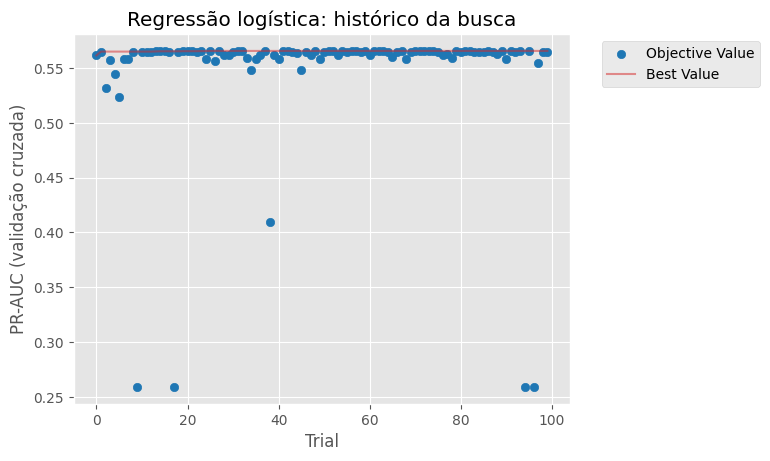

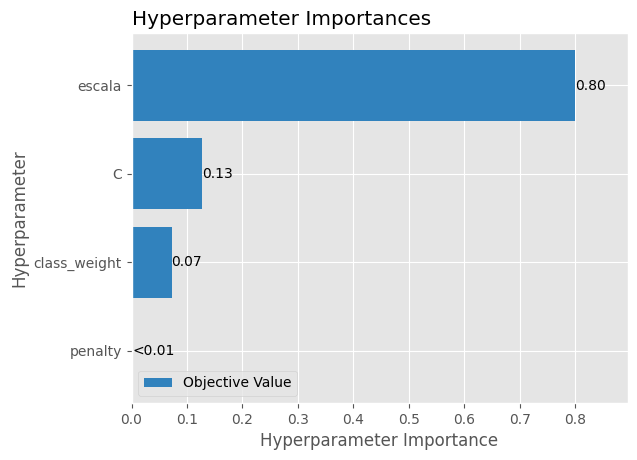

In [26]:
import warnings
import matplotlib.pyplot as plt
from optuna.exceptions import ExperimentalWarning
from optuna.visualization.matplotlib import plot_param_importances, plot_optimization_history

warnings.filterwarnings("ignore", category=ExperimentalWarning)

ax = plot_optimization_history(objeto_de_estudo)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("Regressão logística: histórico da busca")
plt.show()

plot_param_importances(objeto_de_estudo)
plt.show()

Podemos observar que o hiperparâmetro escala é o mais importante para o modelo, e que os trials tiveram resultados parecidos para o pr_auc.

Finalmente, vamos criar um modelo com os melhores hiperparâmetros encontrados pelo Optuna e checar seu desempenho.

In [27]:
logreg_otimizada = cria_instancia_modelo(melhor_trial)

res_lr_otimizada = cross_validate(logreg_otimizada, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_lr_otimizada['test_' + nome].mean():.3f}")
    

accuracy: 0.781
precisao: 0.633
recall: 0.372
f1: 0.468
pr_auc: 0.566
roc_auc: 0.790



A melhora dos valores padrões para o Optuna foi bem baixa, de 0.558 para 0.5655 no pr_auc. Por isso, não da pra afirmar que a otimização melhorou de verdade. Contudo, como a regressão logística é um modelo simples, com pouco o que ajustar, o resultado é que o padrão já estava perto do melhor.

### Algoritmo K-NN

Com isso, vamos seguir para o próximo modelo usando o algoritmo K-NN.

## Referências

https://archive.ics.uci.edu/dataset/880/support2 

https://medium.com/data-hackers/principais-m%C3%A9tricas-de-classifica%C3%A7%C3%A3o-de-modelos-em-machine-learning-94eeb4b40ea9

https://optuna.readthedocs.io/en/stable/index.html

ATP-203 7.1 - Otimização de hiperparâmetros com optuna